# Multivariate Student T distribution



In [1]:
# import relevant packages
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

## Problem 1

The multivariate Student T distribution $\mathbf{X} \sim t(\boldsymbol{\mu}, \boldsymbol{\Sigma}, \nu)$ can be simulated using  [`scipy.stats.multivariate_t`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_t.html#scipy.stats.multivariate_t) and has the density

$$
f_{\mathbf{X}}({\mathbf{x}})  = \frac{\Gamma\left[(\nu+p)/2\right]}{\Gamma(\nu/2)\nu^{p/2}\pi^{p/2}\left|{\boldsymbol\Sigma}\right|^{1/2}}\left[1+\frac{1}{\nu}({\mathbf x}-{\boldsymbol\mu})^{\rm T}{\boldsymbol\Sigma}^{-1}({\mathbf x}-{\boldsymbol\mu})\right]^{-(\nu+p)/2}
$$

where $p$ is the length of the random vector, $\nu$ is the degree of freedoms, $\boldsymbol{\mu}$ is a $p \times 1$ vector and $\boldsymbol{\Sigma}$ is a $p \times p$ positive definite matrix. 

The expected value is given by (if $\nu > 1$)

$$
\text{E} [\mathbf{X}] = \boldsymbol{\mu}
$$

and the covariance matrix (if $\nu > 2$)

$$
\text{Cov} [\mathbf{X}] = \frac{\nu}{\nu - 2} \boldsymbol{\Sigma}
$$

Validate the formula for a bivariate multivariate t distribution with $\boldsymbol{\mu} = (0, 0)^\top$, $\boldsymbol{\Sigma} = \mathbb{I}_2$ and $\nu = 10$ using simulation. Use at least 999 999 simulations. 

In [2]:
"""
Simulate from bivariate Student's t distribution
"""

mu = np.array([0.0, 0.0])
sigma = np.eye(2)
nu = 10
num_sim = 1_000_000

samples = stats.multivariate_t.rvs(loc=mu, shape=sigma, df=nu, size=num_sim)

"""
Compare simulated vs theoretical mean and covariance
"""

sim_mean = samples.mean(axis=0)
sim_cov = np.cov(samples, rowvar=False)
theoretical_cov = nu / (nu - 2) * sigma

print('Simulated mean:', sim_mean)
print('Theoretical mean:', mu)
print('Simulated covariance:\n', sim_cov)
print('Theoretical covariance:\n', theoretical_cov)

Simulated mean: [ 0.00035831 -0.00030438]
Theoretical mean: [0. 0.]
Simulated covariance:
 [[1.24753801e+00 3.00864494e-04]
 [3.00864494e-04 1.25093243e+00]]
Theoretical covariance:
 [[1.25 0.  ]
 [0.   1.25]]


**Tolkning:** We generate a million random points from the multivariate t distribution and check: does our sample's average and spread match the formula's prediction? They should be very close — confirming the formulas actually work in practice, not just on paper.

## Problem 2

Consider the case with $p = 100$ with $\boldsymbol{\mu} = \mathbf{0}$ and $\boldsymbol{\Sigma} = \mathbb{I}_p$. 

Verify using simulations that $\sum_{i=1}^p X_i = \mathbf{1}^\top \mathbf{X} \sim t(0, p, \nu)$. 

Text(0.5, 1.0, 'Sum of Multivariate t Elements vs. Theoretical Distribution')

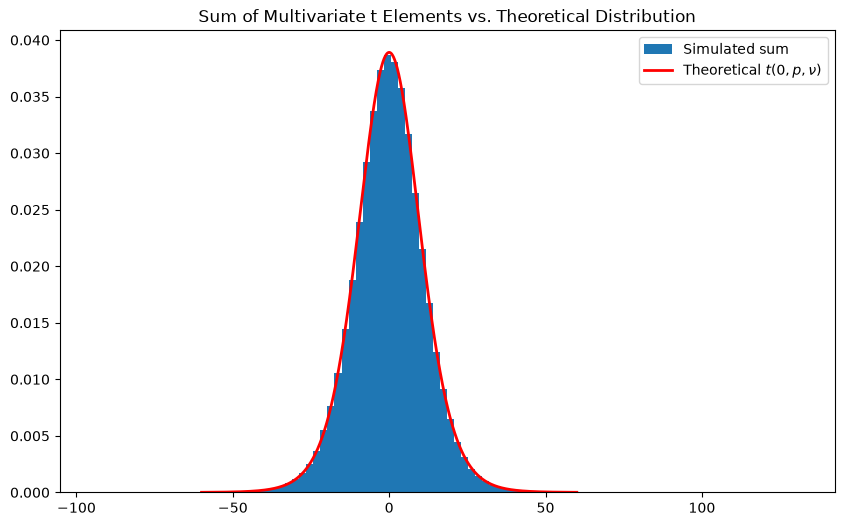

In [3]:
"""
Simulate from 100-dimensional Student's t distribution and sum the elements
"""

p = 100
mu_vec = np.zeros(p)
sigma_mat = np.eye(p)
nu = 10
num_sim = 1_000_000

samples_p = stats.multivariate_t.rvs(loc=mu_vec, shape=sigma_mat, df=nu, size=num_sim)
sum_X = samples_p.sum(axis=1)

"""
Compare with theoretical t(0, p, nu) distribution
"""

x_vals = np.linspace(-60, 60, 1000)
pdf_theoretical = stats.t.pdf(x_vals, df=nu, loc=0, scale=np.sqrt(p))

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(sum_X, bins=100, density=True, label='Simulated sum')
ax.plot(x_vals, pdf_theoretical, color='red', linewidth=2, label='Theoretical $t(0, p, \\nu)$')
ax.legend()
ax.set_title('Sum of Multivariate t Elements vs. Theoretical Distribution')

**Tolkning:** All 100 numbers in each draw share the same hidden "randomness scaling factor" (that's what makes it a multivariate t, not just 100 separate t-distributions). Adding them together still gives us a nice, predictable t-shaped distribution — just wider (scaled by √p). The simulated histogram should match the red theoretical curve closely.

## Problem 3

For the above cases the marginal distribution will be $X_i \sim t(0, 1, \nu)$. Verify that uncorrelated Student t distributed variables cannot be independent by simulating $\sum_{i=1}^p Y_i$ with $Y_i \sim t(0, 1, \nu)$ and comparing the histogram with the theoretical distribution derived above. Additionally, try to add the pdf of a $N(0, p \frac{\nu}{\nu - 2})$ random variable. 

Text(0.5, 1.0, 'Sum of Truly Independent t Variables: Comparison')

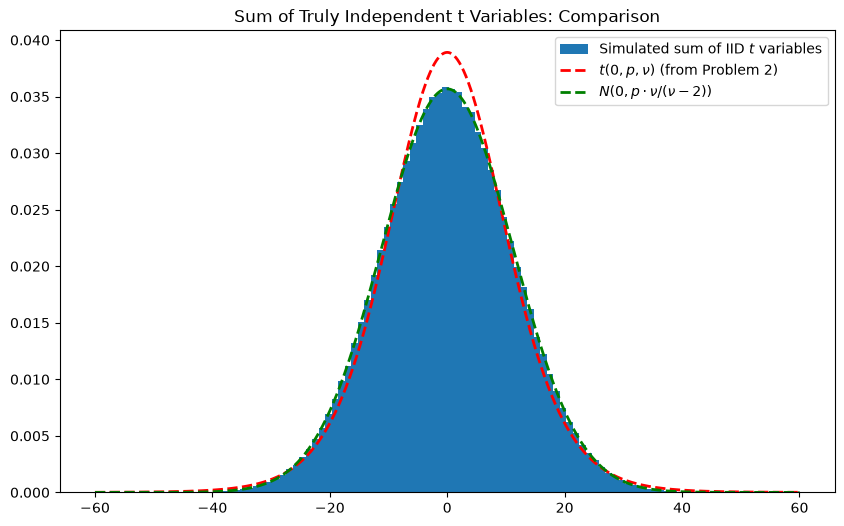

In [4]:
"""
Simulate p INDEPENDENT univariate t(nu) variables and sum them
"""

p = 100
nu = 10
num_sim = 1_000_000

Y = stats.t.rvs(df=nu, size=(num_sim, p))
sum_Y = Y.sum(axis=1)

"""
Compare with the t(0, p, nu) distribution from Problem 2, AND a Normal distribution
"""

x_vals = np.linspace(-60, 60, 1000)
pdf_t_theoretical = stats.t.pdf(x_vals, df=nu, loc=0, scale=np.sqrt(p))
pdf_normal = stats.norm.pdf(x_vals, loc=0, scale=np.sqrt(p * nu / (nu - 2)))

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(sum_Y, bins=100, density=True, label='Simulated sum of IID $t$ variables')
ax.plot(x_vals, pdf_t_theoretical, color='red', linestyle='--', linewidth=2, label='$t(0, p, \\nu)$ (from Problem 2)')
ax.plot(x_vals, pdf_normal, color='green', linestyle='--', linewidth=2, label='$N(0, p\\cdot\\nu/(\\nu-2))$')
ax.legend()
ax.set_title('Sum of Truly Independent t Variables: Comparison')

**Tolkning:** This time, we sum 100 TRULY independent t-distributed numbers — no shared randomness factor. The resulting histogram does NOT match the red curve (the t-distribution from Problem 2) anymore — it's narrower and looks much closer to the green Normal curve instead. This proves the key point: two sets of variables can look identical individually (same marginal distribution, zero correlation) and still behave completely differently when combined, because they're independent vs. dependent in a way correlation alone can't detect.